<a href="https://colab.research.google.com/github/yyymaaa/PCOS_ML_analysis/blob/main/PCOS_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integrated Differential Gene Expression, Functional Enrichment and Machine Learning Analysis of PCOS Using Cumulus Cell RNA-Sequencing Data

**Research Area:** Gene Expression Analysis and Machine Learning  
**Dataset:** GSE277906 – NCBI Gene Expression Omnibus (GEO)

| Role| Assigned To |
|---|---|
| Data acquisition | Nancy Njoroge |
| Data preprocessing and quality control | Macklee Gitonga |
| Exploratory data analysis (EDA) | Bilgis Nzembi |
| Core Analysis | Nicole Agufana |
| Biological interpretation | Phoebe Mokoit |
| Machine learning classification model and Conclusions | Amy Ojuka |

## References

- **PyDESeq2 Documentation:** https://pydeseq2.readthedocs.io/en/latest/
- **Differential Expression in Python with PyDESeq2 (YouTube):** https://www.youtube.com/watch?v=wIvxFEMQVwg
- **NYU Bulk RNA-seq Tutorial:** https://learn.gencore.bio.nyu.edu/transcriptomics/bulk_rna_seq.html

## 1. Introduction

### 1.1 Background

Polycystic Ovary Syndrome (PCOS) is a hormonal and metabolic condition that affects women's reproductive health. Studying the molecular changes linked to PCOS can help explain some of the biological processes involved.

Gene expression analysis makes it possible to compare the activity of genes in people with PCOS and those without the condition.

This study focuses on cumulus cells, which surround developing oocytes. It examines gene expression in these cells to identify genes and biological pathways that may differ between women with PCOS and non-PCOS controls.

The study will also explore whether machine learning can use these gene expression patterns to distinguish between the two groups.

### 1.2 Problem Statement

Although PCOS has been widely studied, its underlying molecular mechanisms still require further investigation. Differences in gene expression may help identify biological processes associated with the condition.

This project analyses RNA-sequencing data from cumulus cells of women with PCOS and non-PCOS controls. It aims to identify differentially expressed genes, examine their biological significance and assess whether these differences can help classify samples into the two groups.

## 2. Research Question and Objectives

### 2.1 Research Question

Which genes and biological pathways are differentially expressed in cumulus cells from women with Polycystic Ovary Syndrome (PCOS) compared with non-PCOS controls, and can these gene expression differences be used to accurately classify samples into the two groups?

### 2.2 Research Objectives

The project will be guided by the following objectives:

1. To obtain, preprocess and assess the quality of publicly available RNA-sequencing data from PCOS and non-PCOS cumulus-cell samples.

2. To identify genes with significant expression differences between the two groups using statistical analysis and false discovery rate correction.

3. To examine the biological significance of the identified genes through pathway enrichment analysis and visualise relevant biological networks using Cytoscape.

4. To develop and evaluate exploratory machine learning models that classify PCOS and non-PCOS samples using gene expression data.

## 3. Dataset Selection and Description

### 3.1 Data Source

The study will use publicly available biological data obtained from the National Center for Biotechnology Information (NCBI) Gene Expression Omnibus (GEO).

### 3.2 Selected Dataset

The selected dataset is GSE277906.

**Dataset accession number:** GSE277906

**Database:** NCBI Gene Expression Omnibus (GEO)

**Dataset link:** https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE277906

### 3.3 Dataset Suitability

GSE277906 was selected for its RNA-sequencing data on gene expression in cumulus cells from women with PCOS and non-PCOS controls.

Its suitability was assessed by examining the available expression data, sample information, experimental details and group labels.

## 4. Research Methodology

The project follows a computational bioinformatics workflow. This includes data acquisition, preprocessing, exploratory analysis, differential gene expression analysis, biological interpretation and machine learning.

Python and relevant bioinformatics libraries are used to carry out the analysis in Google Colab.

The main stages are:

1. Data acquisition and inspection.
2. Data preprocessing and quality control.
3. Exploratory data analysis.
4. Differential gene expression analysis.
5. Biological interpretation and pathway enrichment.
6. Biological network visualisation using Cytoscape.
7. Machine learning classification and model evaluation.
8. Discussion, conclusions and recommendations.

## 5. Data Acquisition and Initial Inspection

This stage involves obtaining the RNA-sequencing data and sample metadata from the NCBI Gene Expression Omnibus (GEO).

The study uses GSE277906, which contains gene expression data from human cumulus cells collected from women with PCOS and non-PCOS controls.

The raw gene count matrix is used as the main input for differential gene expression analysis.

In [1]:
import pandas as pd
import numpy as np
import requests
import gzip
import os
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from io import BytesIO

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 10)

DATA_DIR = Path("/content/pcos_project")
DATA_DIR.mkdir(parents=True, exist_ok=True)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
base_url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE277nnn/GSE277906/suppl/"

files = {
    "counts": "GSE277906_counts_anno.txt.gz",
    "fpkm": "GSE277906_FPKM_anno.txt.gz"
}

for name, filename in files.items():
    url = base_url + filename
    response = requests.get(url)

    response.raise_for_status()

    output_path = DATA_DIR / filename

    with open(output_path, "wb") as file:
        file.write(response.content)

    print(f"{name.upper()} file downloaded successfully.")

COUNTS file downloaded successfully.
FPKM file downloaded successfully.


In [3]:
counts_path = DATA_DIR / files["counts"]
fpkm_path = DATA_DIR / files["fpkm"]

counts = pd.read_csv(counts_path, sep="\t", compression="gzip")
fpkm = pd.read_csv(fpkm_path, sep="\t", compression="gzip")

print("Raw count matrix shape:", counts.shape)
print("FPKM matrix shape:", fpkm.shape)

display(counts.head())

Raw count matrix shape: (28001, 52)
FPKM matrix shape: (28001, 52)


,id,Control1,Control10,Control11,Control12,Control13,Control14,Control15,Control16,Control17,Control2,Control3,Control4,Control5,Control6,Control7,Control8,Control9,PCOS1,PCOS10,PCOS11,PCOS12,PCOS13,PCOS14,PCOS15,PCOS16,PCOS17,PCOS18,PCOS19,PCOS2,PCOS20,PCOS21,PCOS22,PCOS23,PCOS3,PCOS4,PCOS5,PCOS6,PCOS7,PCOS8,PCOS9,gene_Dbxref,coding_type,description,pathway,pathway_description,GO_ID,GO_term,wiki_ID,wiki_term,Reactome_ID,Reactome_term
0,A1BG,329,504,709,546,865,779,695,768,422,688,638,797,393,1258,1108,401,736,678,387,389,546,345,579,421,1462,741,463,676,977,1182,729,727,1086,398,778,794,437,608,656,574,1,protein_coding,alpha-1-B glycoprotein,NaN,NaN,"GO:0003674,GO:0005576,GO:0005615,GO:0005886,GO...",molecular_function|extracellular region|extrac...,NaN,NaN,"R-HSA-109582,R-HSA-114608,R-HSA-168249,R-HSA-1...",Hemostasis|Platelet degranulation |Innate Immu...
1,A1BG-AS1,287,217,296,452,390,372,501,232,399,421,428,594,388,720,713,320,341,420,296,275,505,322,506,254,446,511,355,418,472,393,326,558,281,275,734,605,278,527,564,543,503538,non_coding,A1BG antisense RNA 1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A2M,1458,160,52,26,93,39,48,13,232,194,88,103,95,98,59,36,15,15,36,19,15,117,184,75,22,58,43,22,44,43,22,16,99,30,48,20,54,22,23,29,2,protein_coding,alpha-2-macroglobulin,hsa04610,Complement and coagulation cascades,"GO:0001553,GO:0001869,GO:0002020,GO:0002438,GO...",luteinization|negative regulation of complemen...,NaN,NaN,"R-HSA-109582,R-HSA-114608,R-HSA-140837,R-HSA-1...",Hemostasis|Platelet degranulation |Intrinsic P...
3,A2M-AS1,11,0,0,12,5,2,24,0,18,5,2,1,0,3,0,4,0,20,10,0,30,0,4,10,1,18,2,16,27,2,4,6,0,39,22,35,3,9,8,15,144571,non_coding,A2M antisense RNA 1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,A2ML1,9,0,11,3,0,9,5,4,1,0,0,11,10,0,0,0,12,1,0,10,9,2,11,0,11,1,28,5,0,0,6,0,8,13,0,3,1,12,5,0,144568,protein_coding,alpha-2-macroglobulin like 1,NaN,NaN,"GO:0004867,GO:0005615,GO:0010466,GO:0030414,GO...",serine-type endopeptidase inhibitor activity|e...,NaN,NaN,NaN,NaN


In [4]:
print("Column names:")
print(counts.columns.tolist())

print("\nData types:")
print(counts.dtypes)

print("\nDataset information:")
counts.info()

print("\nFirst five rows:")
display(counts.head())

Column names:
['id', 'Control1', 'Control10', 'Control11', 'Control12', 'Control13', 'Control14', 'Control15', 'Control16', 'Control17', 'Control2', 'Control3', 'Control4', 'Control5', 'Control6', 'Control7', 'Control8', 'Control9', 'PCOS1', 'PCOS10', 'PCOS11', 'PCOS12', 'PCOS13', 'PCOS14', 'PCOS15', 'PCOS16', 'PCOS17', 'PCOS18', 'PCOS19', 'PCOS2', 'PCOS20', 'PCOS21', 'PCOS22', 'PCOS23', 'PCOS3', 'PCOS4', 'PCOS5', 'PCOS6', 'PCOS7', 'PCOS8', 'PCOS9', 'gene_Dbxref', 'coding_type', 'description', 'pathway', 'pathway_description', 'GO_ID', 'GO_term', 'wiki_ID', 'wiki_term', 'Reactome_ID', 'Reactome_term']

Data types:
id                 str
Control1         int64
Control10        int64
Control11        int64
Control12        int64
                 ...  
GO_term            str
wiki_ID            str
wiki_term          str
Reactome_ID        str
Reactome_term      str
Length: 52, dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 28001 entries, 0 to 28000
Data columns

,id,Control1,Control10,Control11,Control12,Control13,Control14,Control15,Control16,Control17,Control2,Control3,Control4,Control5,Control6,Control7,Control8,Control9,PCOS1,PCOS10,PCOS11,PCOS12,PCOS13,PCOS14,PCOS15,PCOS16,PCOS17,PCOS18,PCOS19,PCOS2,PCOS20,PCOS21,PCOS22,PCOS23,PCOS3,PCOS4,PCOS5,PCOS6,PCOS7,PCOS8,PCOS9,gene_Dbxref,coding_type,description,pathway,pathway_description,GO_ID,GO_term,wiki_ID,wiki_term,Reactome_ID,Reactome_term
0,A1BG,329,504,709,546,865,779,695,768,422,688,638,797,393,1258,1108,401,736,678,387,389,546,345,579,421,1462,741,463,676,977,1182,729,727,1086,398,778,794,437,608,656,574,1,protein_coding,alpha-1-B glycoprotein,NaN,NaN,"GO:0003674,GO:0005576,GO:0005615,GO:0005886,GO...",molecular_function|extracellular region|extrac...,NaN,NaN,"R-HSA-109582,R-HSA-114608,R-HSA-168249,R-HSA-1...",Hemostasis|Platelet degranulation |Innate Immu...
1,A1BG-AS1,287,217,296,452,390,372,501,232,399,421,428,594,388,720,713,320,341,420,296,275,505,322,506,254,446,511,355,418,472,393,326,558,281,275,734,605,278,527,564,543,503538,non_coding,A1BG antisense RNA 1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A2M,1458,160,52,26,93,39,48,13,232,194,88,103,95,98,59,36,15,15,36,19,15,117,184,75,22,58,43,22,44,43,22,16,99,30,48,20,54,22,23,29,2,protein_coding,alpha-2-macroglobulin,hsa04610,Complement and coagulation cascades,"GO:0001553,GO:0001869,GO:0002020,GO:0002438,GO...",luteinization|negative regulation of complemen...,NaN,NaN,"R-HSA-109582,R-HSA-114608,R-HSA-140837,R-HSA-1...",Hemostasis|Platelet degranulation |Intrinsic P...
3,A2M-AS1,11,0,0,12,5,2,24,0,18,5,2,1,0,3,0,4,0,20,10,0,30,0,4,10,1,18,2,16,27,2,4,6,0,39,22,35,3,9,8,15,144571,non_coding,A2M antisense RNA 1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,A2ML1,9,0,11,3,0,9,5,4,1,0,0,11,10,0,0,0,12,1,0,10,9,2,11,0,11,1,28,5,0,0,6,0,8,13,0,3,1,12,5,0,144568,protein_coding,alpha-2-macroglobulin like 1,NaN,NaN,"GO:0004867,GO:0005615,GO:0010466,GO:0030414,GO...",serine-type endopeptidase inhibitor activity|e...,NaN,NaN,NaN,NaN


## 5.1 Initial Dataset Inspection

The downloaded dataset contains two expression matrices, a raw gene count matrix and an FPKM matrix. Both have 28,001 rows and 52 columns.

The raw count matrix contains 40 sample columns, with 17 control samples and 23 PCOS samples. The remaining columns contain gene identifiers and annotations.

Gene symbols are stored in the id column. Other annotations include gene descriptions, coding types, pathway information, Gene Ontology terms and Reactome information.

The raw counts are retained for differential gene expression analysis, while the FPKM matrix is used for exploratory expression visualisation.

In [5]:
sample_cols = [
    col for col in counts.columns
    if col.startswith("Control") or col.startswith("PCOS")
]

control_samples = [col for col in sample_cols if col.startswith("Control")]
pcos_samples = [col for col in sample_cols if col.startswith("PCOS")]

print("Total samples:", len(sample_cols))
print("Control samples:", len(control_samples))
print("PCOS samples:", len(pcos_samples))

print("\nControl samples:", sorted(control_samples))
print("\nPCOS samples:", sorted(pcos_samples))

Total samples: 40
Control samples: 17
PCOS samples: 23

Control samples: ['Control1', 'Control10', 'Control11', 'Control12', 'Control13', 'Control14', 'Control15', 'Control16', 'Control17', 'Control2', 'Control3', 'Control4', 'Control5', 'Control6', 'Control7', 'Control8', 'Control9']

PCOS samples: ['PCOS1', 'PCOS10', 'PCOS11', 'PCOS12', 'PCOS13', 'PCOS14', 'PCOS15', 'PCOS16', 'PCOS17', 'PCOS18', 'PCOS19', 'PCOS2', 'PCOS20', 'PCOS21', 'PCOS22', 'PCOS23', 'PCOS3', 'PCOS4', 'PCOS5', 'PCOS6', 'PCOS7', 'PCOS8', 'PCOS9']


In [6]:
gene_annotations = counts.drop(columns=sample_cols).copy()

count_matrix = counts[["id"] + sample_cols].copy()
count_matrix = count_matrix.set_index("id")

count_matrix = count_matrix.apply(pd.to_numeric, errors="raise")

fpkm_matrix = fpkm[["id"] + sample_cols].copy()
fpkm_matrix = fpkm_matrix.set_index("id")
fpkm_matrix = fpkm_matrix.apply(pd.to_numeric, errors="raise")

print("Count matrix:", count_matrix.shape)
print("FPKM matrix:", fpkm_matrix.shape)
print("\nGene annotations:", gene_annotations.shape)

display(count_matrix.head())

Count matrix: (28001, 40)
FPKM matrix: (28001, 40)

Gene annotations: (28001, 12)


,Control1,Control10,Control11,Control12,Control13,Control14,Control15,Control16,Control17,Control2,Control3,Control4,Control5,Control6,Control7,Control8,Control9,PCOS1,PCOS10,PCOS11,PCOS12,PCOS13,PCOS14,PCOS15,PCOS16,PCOS17,PCOS18,PCOS19,PCOS2,PCOS20,PCOS21,PCOS22,PCOS23,PCOS3,PCOS4,PCOS5,PCOS6,PCOS7,PCOS8,PCOS9
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A1BG,329,504,709,546,865,779,695,768,422,688,638,797,393,1258,1108,401,736,678,387,389,546,345,579,421,1462,741,463,676,977,1182,729,727,1086,398,778,794,437,608,656,574
A1BG-AS1,287,217,296,452,390,372,501,232,399,421,428,594,388,720,713,320,341,420,296,275,505,322,506,254,446,511,355,418,472,393,326,558,281,275,734,605,278,527,564,543
A2M,1458,160,52,26,93,39,48,13,232,194,88,103,95,98,59,36,15,15,36,19,15,117,184,75,22,58,43,22,44,43,22,16,99,30,48,20,54,22,23,29
A2M-AS1,11,0,0,12,5,2,24,0,18,5,2,1,0,3,0,4,0,20,10,0,30,0,4,10,1,18,2,16,27,2,4,6,0,39,22,35,3,9,8,15
A2ML1,9,0,11,3,0,9,5,4,1,0,0,11,10,0,0,0,12,1,0,10,9,2,11,0,11,1,28,5,0,0,6,0,8,13,0,3,1,12,5,0


In [7]:
print("Missing expression values:", count_matrix.isna().sum().sum())
print("Negative expression values:", (count_matrix < 0).sum().sum())
print("Non-integer count values:",
      (count_matrix % 1 != 0).sum().sum())

print("Duplicate gene symbols:", count_matrix.index.duplicated().sum())
print("Genes with all-zero counts:", (count_matrix.sum(axis=1) == 0).sum())

Missing expression values: 0
Negative expression values: 0
Non-integer count values: 0
Duplicate gene symbols: 0
Genes with all-zero counts: 0


## 5.2 Quality Control Assessment

Quality control was carried out to check the completeness and consistency of the expression data before further analysis.

The assessment includes:

- Checking for missing and negative expression values.
- Identifying duplicate gene identifiers.
- Checking for genes with zero expression across all samples.
- Comparing sequencing library sizes across samples.
- Examining gene expression distributions.

,Sample,Group,Library_Size
0,PCOS3,PCOS,41375119
1,PCOS17,PCOS,41293737
2,Control4,Control,41232920
3,PCOS12,PCOS,40984405
4,PCOS11,PCOS,40708916
...,...,...,...
35,PCOS20,PCOS,33612390
36,PCOS23,PCOS,33544221
37,Control5,Control,33194931
38,PCOS6,PCOS,32596285


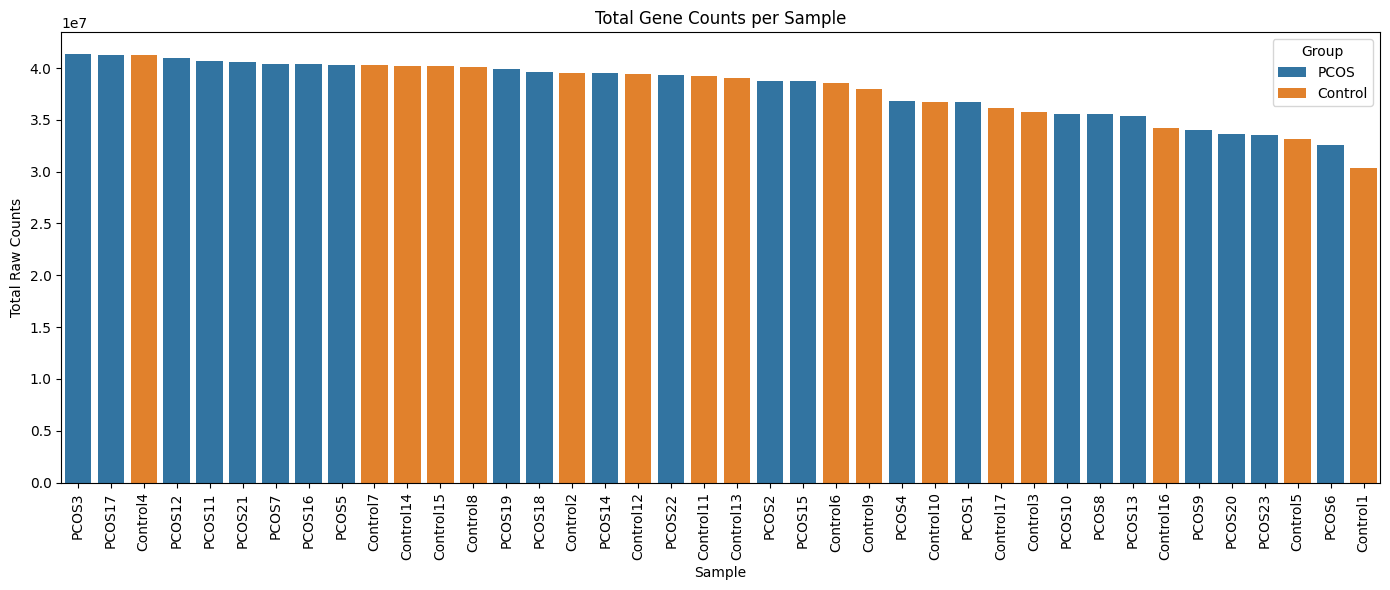

In [8]:
library_sizes = count_matrix.sum(axis=0).sort_values(ascending=False)

library_summary = pd.DataFrame({
    "Sample": library_sizes.index,
    "Group": [
        "Control" if s.startswith("Control") else "PCOS"
        for s in library_sizes.index
    ],
    "Library_Size": library_sizes.values
})

display(library_summary)

plt.figure(figsize=(14, 6))
sns.barplot(
    data=library_summary,
    x="Sample",
    y="Library_Size",
    hue="Group"
)

plt.title("Total Gene Counts per Sample")
plt.xlabel("Sample")
plt.ylabel("Total Raw Counts")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [9]:
zero_counts = (count_matrix == 0).sum(axis=1)

zero_summary = pd.DataFrame({
    "Metric": [
        "Total genes",
        "Genes with zero counts in all samples",
        "Genes with at least one zero count",
        "Genes expressed in every sample"
    ],
    "Count": [
        len(count_matrix),
        (zero_counts == len(sample_cols)).sum(),
        (zero_counts > 0).sum(),
        (zero_counts == 0).sum()
    ]
})

display(zero_summary)

,Metric,Count
0,Total genes,28001
1,Genes with zero counts in all samples,0
2,Genes with at least one zero count,14723
3,Genes expressed in every sample,13278


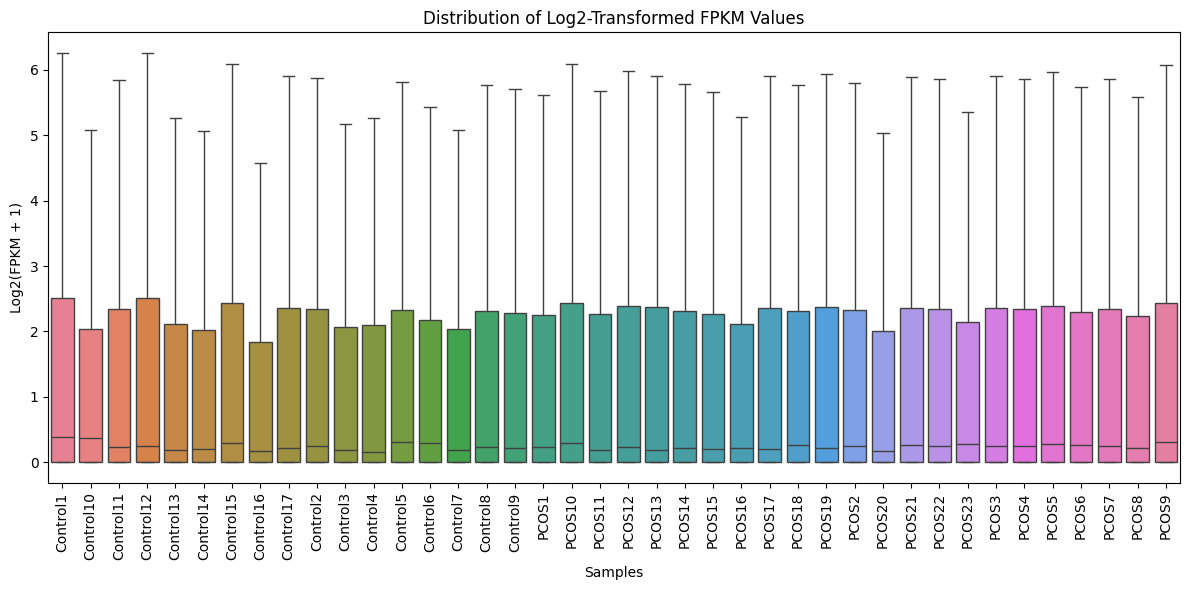

In [10]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=np.log2(fpkm_matrix + 1),
    showfliers=False
)

plt.title("Distribution of Log2-Transformed FPKM Values")
plt.xlabel("Samples")
plt.ylabel("Log2(FPKM + 1)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 5.3 Quality Control Results

The quality control checks found no missing or negative expression values, non-integer raw counts, duplicate gene identifiers or genes with zero counts across all samples.

The dataset contains 28,001 genes. Of these, 14,723 have zero counts in at least one sample, while 13,278 have non-zero counts across all samples.

Library sizes varied across the samples, showing the need for normalization before comparing expression between the PCOS and control groups. The FPKM distribution plots showed broadly similar expression patterns across samples.

Overall, the initial checks did not identify any issues that required sample removal. All samples were retained for further preprocessing and analysis.

In [11]:
metadata = pd.DataFrame({
    "sample": sample_cols,
    "condition": [
        "Control" if sample.startswith("Control") else "PCOS"
        for sample in sample_cols
    ]
})

metadata = metadata.set_index("sample")
count_matrix = count_matrix[metadata.index]

display(metadata)
print(metadata["condition"].value_counts())

,condition
sample,
Control1,Control
Control10,Control
Control11,Control
Control12,Control
Control13,Control
...,...
PCOS5,PCOS
PCOS6,PCOS
PCOS7,PCOS


condition
PCOS       23
Control    17
Name: count, dtype: int64


In [12]:
gene_counts_per_sample = (count_matrix >= 10).sum(axis=1)

filtered_count_matrix = count_matrix.loc[
    gene_counts_per_sample >= 2
].copy()

print("Original number of genes:", count_matrix.shape[0])
print("Genes after filtering:", filtered_count_matrix.shape[0])
print("Genes removed:", count_matrix.shape[0] - filtered_count_matrix.shape[0])

Original number of genes: 28001
Genes after filtering: 19216
Genes removed: 8785


## 6. Exploratory Data Analysis

Exploratory data analysis was used to examine gene expression patterns and variation across the PCOS and control samples.

The analysis includes:
- Comparing gene expression distributions between the two groups.
- Examining similarities between samples using correlation analysis.
- Using Principal Component Analysis (PCA) to explore sample clustering and variation.

In [13]:
fpkm_filtered = fpkm_matrix.loc[
    fpkm_matrix.index.isin(filtered_count_matrix.index)
].copy()

log_fpkm = np.log2(fpkm_filtered + 1)

print("Filtered FPKM matrix:", log_fpkm.shape)

Filtered FPKM matrix: (19216, 40)


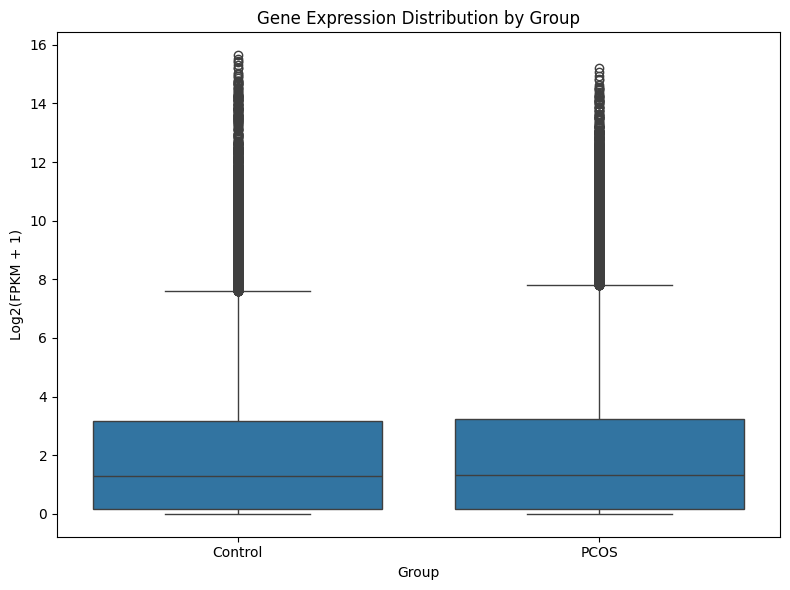

In [14]:
expression_data = log_fpkm.T.join(metadata)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=expression_data.melt(
        id_vars="condition",
        var_name="Gene",
        value_name="Expression"
    ),
    x="condition",
    y="Expression"
)
plt.title("Gene Expression Distribution by Group")
plt.xlabel("Group")
plt.ylabel("Log2(FPKM + 1)")
plt.tight_layout()
plt.show()

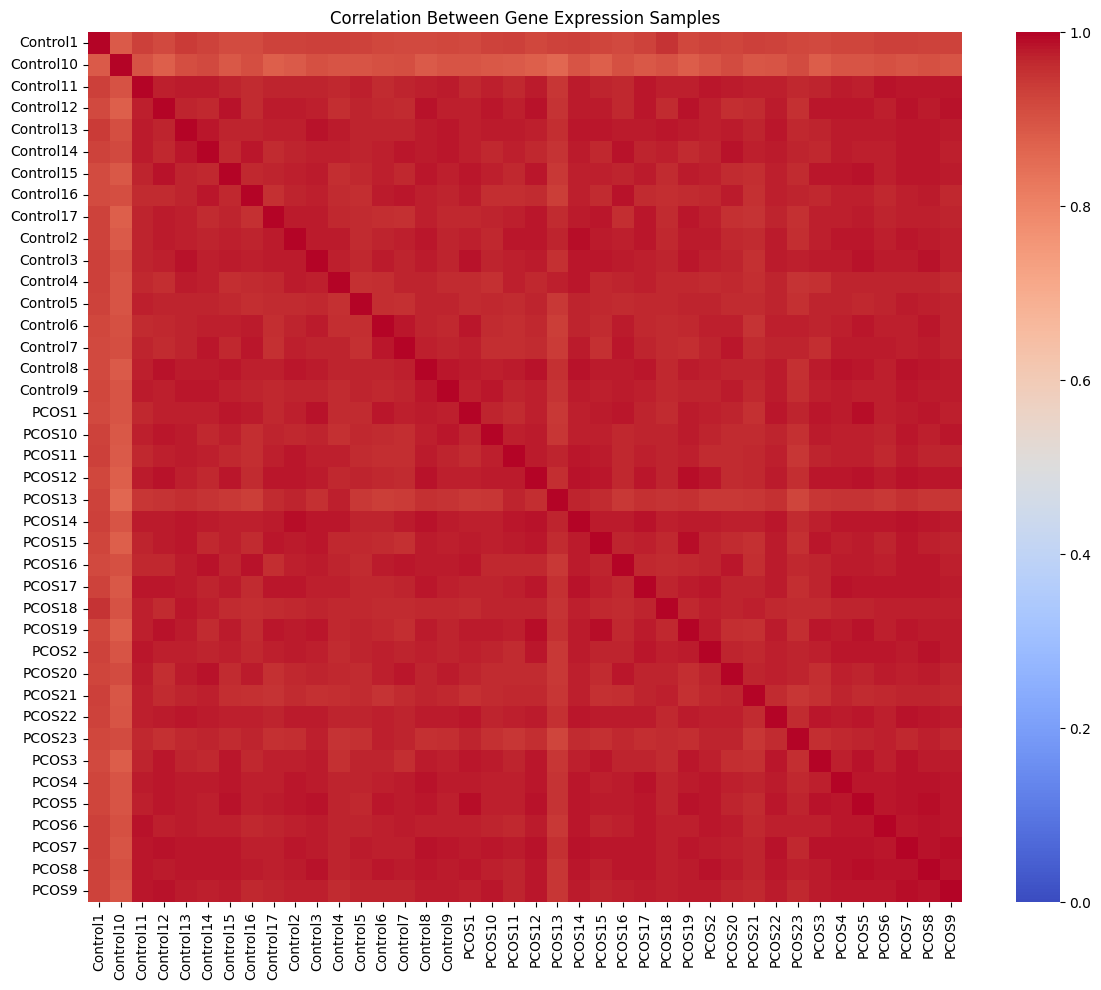

In [15]:
sample_correlation = log_fpkm.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    sample_correlation,
    cmap="coolwarm",
    vmin=0,
    vmax=1
)
plt.title("Correlation Between Gene Expression Samples")
plt.tight_layout()
plt.show()

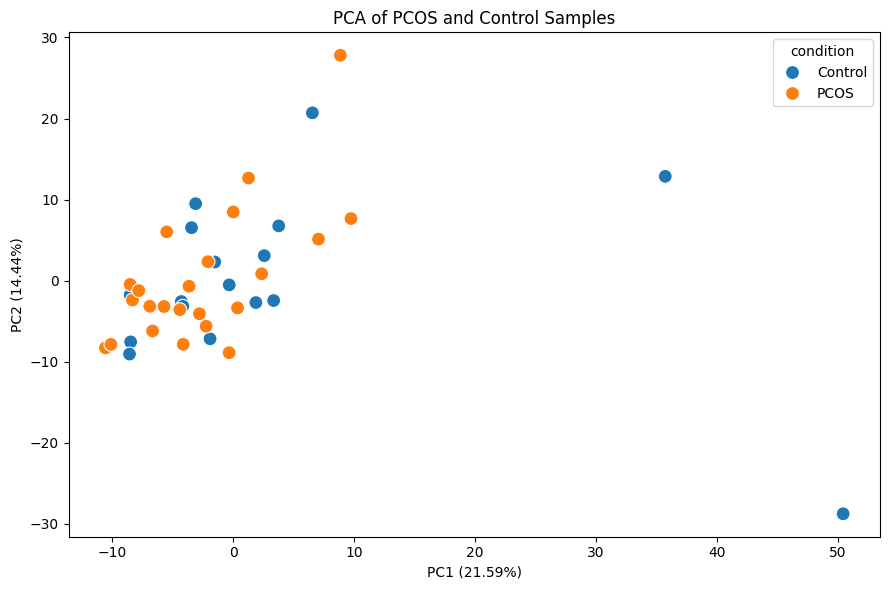

Explained variance: [0.21585999 0.14442645]


In [16]:
from sklearn.decomposition import PCA

gene_variances = log_fpkm.var(axis=1)
top_genes = gene_variances.nlargest(500).index

pca_data = log_fpkm.loc[top_genes].T

pca = PCA(n_components=2)
pca_results = pca.fit_transform(pca_data)

pca_df = pd.DataFrame(
    pca_results,
    columns=["PC1", "PC2"],
    index=pca_data.index
).join(metadata)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="condition",
    s=100
)
plt.title("PCA of PCOS and Control Samples")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)")
plt.tight_layout()
plt.show()

print("Explained variance:", pca.explained_variance_ratio_)

### 6.4 Summary of Exploratory Data Analysis

The expression distributions were broadly similar between the PCOS and control groups. The sample correlation analysis also showed strong similarities, with Pearson correlation values ranging from approximately 0.85 to 1.00.

PCA showed that PC1 explained 21.59% of the total variance, while PC2 explained 14.44%. Together, they accounted for 36.03% of the variance. The PCOS and control samples overlapped considerably, meaning that the first two components did not clearly separate the groups.

A few samples appeared further away from the main PCA cluster. This may reflect biological or technical variation and could require further investigation.

Overall, the samples showed similar global expression patterns. Further statistical analysis was needed to identify specific genes with differences between the two groups.

## 7. Differential Gene Expression Analysis

Differential gene expression analysis was used to identify genes with significant expression differences between women with PCOS and non-PCOS controls.

The analysis used the filtered raw gene count matrix and sample metadata. PyDESeq2 was used for normalization, estimating gene expression variability and statistical testing.

Genes with adjusted p-values below 0.05 were considered significantly differentially expressed. Log2 fold change was used to show the direction and size of the expression differences.

In [17]:
!pip install pydeseq2

In [18]:
import pandas as pd
import numpy as np
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

dds_counts = filtered_count_matrix.T.copy()
dds_counts = dds_counts.astype(int)

dds_metadata = metadata.copy()
dds_metadata["condition"] = pd.Categorical(
    dds_metadata["condition"],
    categories=["Control", "PCOS"]
)

dds_counts = dds_counts.loc[dds_metadata.index]

print("Count data shape:", dds_counts.shape)
print("Metadata shape:", dds_metadata.shape)
print("\nSample groups:")
print(dds_metadata["condition"].value_counts())

Count data shape: (40, 19216)
Metadata shape: (40, 1)

Sample groups:
condition
PCOS       23
Control    17
Name: count, dtype: int64


In [19]:
dds = DeseqDataSet(
    counts=dds_counts,
    metadata=dds_metadata,
    design="~condition",
    refit_cooks=True,
    n_cpus=2
)

print("DESeq2 dataset created successfully.")

DESeq2 dataset created successfully.


In [20]:
dds.deseq2()

print("Differential expression analysis completed.")

Differential expression analysis completed.


In [21]:
stat_res = DeseqStats(
    dds,
    contrast=["condition", "PCOS", "Control"],
    n_cpus=2
)

stat_res.summary()

results_df = stat_res.results_df.copy()
results_df.index.name = "Gene"

display(results_df.head())

print("Total genes analysed:", len(results_df))

Log2 fold change & Wald test p-value: condition PCOS vs Control
              baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
id                                                                            
A1BG        694.907372       -0.127884  0.195687 -0.653513  0.513426  0.962188
A1BG-AS1    419.648998       -0.082810  0.141202 -0.586464  0.557564  0.966616
A2M          63.311335       -0.947757  0.345981 -2.739332  0.006156  0.419754
A2M-AS1       8.411223        1.171643  0.600078  1.952484  0.050881  0.792842
A2ML1         4.918874        0.165824  0.731897  0.226568  0.820760       NaN
...                ...             ...       ...       ...       ...       ...
ZYG11A        7.383770       -0.710034  0.508200 -1.397156  0.162367  0.903181
ZYG11B     1097.535889        0.176308  0.122335  1.441183  0.149533  0.901977
ZYX       21388.001555       -0.044644  0.111440 -0.400610  0.688707  0.977335
ZZEF1      1832.545897       -0.034348  0.076001 -0.451939  0.65131

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Gene,,,,,,
A1BG,694.907372,-0.127884,0.195687,-0.653513,0.513426,0.962188
A1BG-AS1,419.648998,-0.082810,0.141202,-0.586464,0.557564,0.966616
A2M,63.311335,-0.947757,0.345981,-2.739332,0.006156,0.419754
A2M-AS1,8.411223,1.171643,0.600078,1.952484,0.050881,0.792842
A2ML1,4.918874,0.165824,0.731897,0.226568,0.820760,NaN


Total genes analysed: 19216


In [22]:
results_df["significant"] = results_df["padj"] < 0.05

significant_genes = results_df[
    results_df["significant"]
].copy()

upregulated_genes = significant_genes[
    significant_genes["log2FoldChange"] > 0
]

downregulated_genes = significant_genes[
    significant_genes["log2FoldChange"] < 0
]

print("Total genes analysed:", len(results_df))
print("Significantly differentially expressed:", len(significant_genes))
print("Upregulated in PCOS:", len(upregulated_genes))
print("Downregulated in PCOS:", len(downregulated_genes))

Total genes analysed: 19216
Significantly differentially expressed: 15
Upregulated in PCOS: 0
Downregulated in PCOS: 15


In [23]:
top_genes = significant_genes.sort_values(
    by="padj"
).head(20)

display(
    top_genes[
        ["baseMean", "log2FoldChange", "pvalue", "padj"]
    ]
)

,baseMean,log2FoldChange,pvalue,padj
Gene,,,,
S100A9,253.963920,-2.894358,1.476170e-07,0.002449
PECAM1,45.265058,-2.847864,2.961092e-07,0.002456
C15orf48,28.165294,-2.605696,1.152003e-06,0.005786
CCDC88B,110.942067,-2.057110,1.459889e-06,0.005786
RUNX3,18.455156,-3.676012,1.743701e-06,0.005786
...,...,...,...,...
CFD,32.778648,-2.727286,3.422683e-05,0.048552
C1QB,27.446899,-2.404790,3.000299e-05,0.048552
SECTM1,26.882858,-1.927993,3.804341e-05,0.048552


### 7.1 Differential Gene Expression Results

PyDESeq2 was used to analyse 19,216 filtered genes across 40 samples, consisting of 23 PCOS samples and 17 non-PCOS controls.

A total of 15 genes had adjusted p-values below 0.05.

All 15 genes had negative log2 fold changes, meaning their expression was lower in the PCOS group than in the control group. No significantly upregulated genes were identified.

S100A9 had the lowest adjusted p-value at 0.002449, followed by PECAM1 at 0.002456. RUNX3 had the largest negative log2 fold change among the reported top genes, at -3.676.

These results show differences in the expression of specific genes between the two groups. Further pathway enrichment and biological interpretation are needed to understand their possible roles in PCOS.

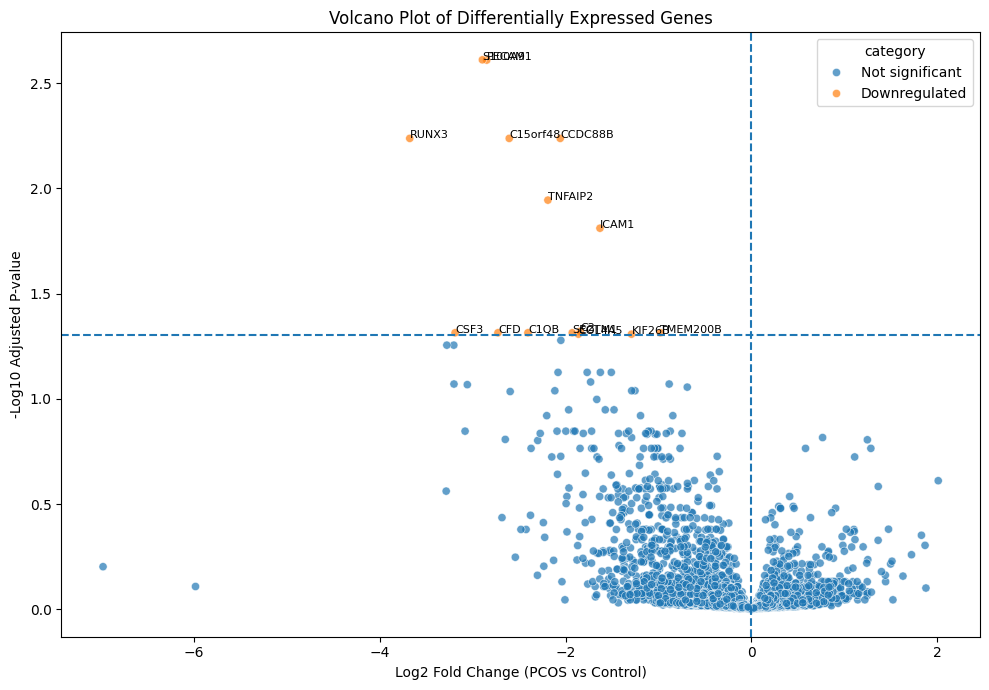

In [24]:
import matplotlib.pyplot as plt
import numpy as np

volcano_df = results_df.dropna(subset=["padj", "log2FoldChange"]).copy()

volcano_df["neg_log10_padj"] = -np.log10(
    volcano_df["padj"].clip(lower=1e-300)
)

volcano_df["category"] = "Not significant"
volcano_df.loc[
    (volcano_df["padj"] < 0.05) &
    (volcano_df["log2FoldChange"] < 0),
    "category"
] = "Downregulated"

volcano_df.loc[
    (volcano_df["padj"] < 0.05) &
    (volcano_df["log2FoldChange"] > 0),
    "category"
] = "Upregulated"

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=volcano_df,
    x="log2FoldChange",
    y="neg_log10_padj",
    hue="category",
    alpha=0.7,
    s=35
)

plt.axhline(-np.log10(0.05), linestyle="--")
plt.axvline(0, linestyle="--")

for gene in significant_genes.index:
    row = volcano_df.loc[gene]
    plt.annotate(
        gene,
        (row["log2FoldChange"], row["neg_log10_padj"]),
        fontsize=8
    )

plt.title("Volcano Plot of Differentially Expressed Genes")
plt.xlabel("Log2 Fold Change (PCOS vs Control)")
plt.ylabel("-Log10 Adjusted P-value")
plt.tight_layout()
plt.show()

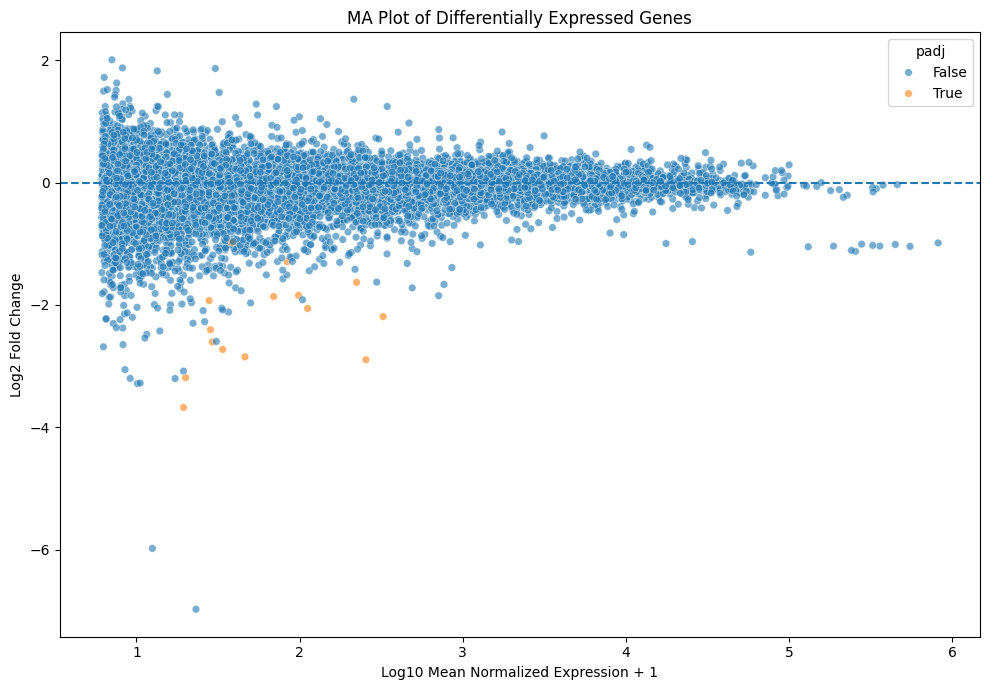

In [25]:
ma_df = results_df.dropna(
    subset=["baseMean", "log2FoldChange", "padj"]
).copy()

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=ma_df,
    x=np.log10(ma_df["baseMean"] + 1),
    y="log2FoldChange",
    hue=ma_df["padj"] < 0.05,
    alpha=0.6,
    s=30
)

plt.axhline(0, linestyle="--")
plt.title("MA Plot of Differentially Expressed Genes")
plt.xlabel("Log10 Mean Normalized Expression + 1")
plt.ylabel("Log2 Fold Change")
plt.tight_layout()
plt.show()

In [26]:
results_df.to_csv(
    "PCOS_differential_expression_results.csv"
)

significant_genes.to_csv(
    "PCOS_significant_genes.csv"
)

print("Differential expression results exported.")

Differential expression results exported.


### 7.2 Visualisation of Differential Expression Results

The volcano plot showed that all significantly differentially expressed genes were on the negative side of the log2 fold change axis. This indicates lower expression in PCOS samples compared with controls. No significantly upregulated genes were found. Some of the notable genes included RUNX3, S100A9, S100A8, C15orf48 and CCDC88B.

The MA plot showed that most significant genes had low to moderate expression levels and negative log2 fold changes. The wider spread of fold changes among genes with lower mean expression indicates greater variation in this range.

Together, the two plots provide a visual summary of the results and show that all 15 significant genes were downregulated in the PCOS group.

## 8. Validation of Differential Expression Results

Additional checks were carried out to confirm the sample group assignments and examine samples that appeared unusual during the analysis.

The validation focused on sample metadata, expression patterns and possible outliers.

In [27]:
print("Sample counts:")
print(metadata["condition"].value_counts())

print("\nSample alignment:")
print("Count matrix samples:", list(dds_counts.index) == list(dds_metadata.index))
print("Metadata samples:", len(metadata))
print("Unique samples:", metadata.index.nunique())

display(metadata)

Sample counts:
condition
PCOS       23
Control    17
Name: count, dtype: int64

Sample alignment:
Count matrix samples: True
Metadata samples: 40
Unique samples: 40


,condition
sample,
Control1,Control
Control10,Control
Control11,Control
Control12,Control
Control13,Control
...,...
PCOS5,PCOS
PCOS6,PCOS
PCOS7,PCOS


In [28]:
pca_inspection = pca_df.copy()

pca_inspection["Distance"] = np.sqrt(
    pca_inspection["PC1"]**2 +
    pca_inspection["PC2"]**2
)

display(
    pca_inspection.sort_values(
        "Distance", ascending=False
    ).head(10)
)

,PC1,PC2,condition,Distance
Control10,50.461926,-28.762808,Control,58.083604
Control1,35.747503,12.868040,Control,37.993031
PCOS13,8.871174,27.803058,PCOS,29.184033
Control4,6.554397,20.700256,Control,21.713146
PCOS1,-10.566338,-8.296057,PCOS,13.433989
PCOS3,-10.105935,-7.866642,PCOS,12.806794
PCOS11,1.274194,12.653065,PCOS,12.717061
Control15,-8.571917,-9.055782,Control,12.469361
PCOS18,9.751620,7.654960,PCOS,12.397278
Control12,-8.478147,-7.555546,Control,11.356287


In [29]:
library_check = library_summary.copy()

display(
    library_check.sort_values(
        "Library_Size", ascending=False
    )
)

,Sample,Group,Library_Size
0,PCOS3,PCOS,41375119
1,PCOS17,PCOS,41293737
2,Control4,Control,41232920
3,PCOS12,PCOS,40984405
4,PCOS11,PCOS,40708916
...,...,...,...
35,PCOS20,PCOS,33612390
36,PCOS23,PCOS,33544221
37,Control5,Control,33194931
38,PCOS6,PCOS,32596285


### 8.1 Validation Summary

The sample metadata was checked and confirmed to contain 40 unique samples, including 23 PCOS samples and 17 controls. The sample metadata and count matrix were correctly aligned.

PCA showed that Control10 and Control1 were relatively distant from the main sample cluster. However, their library sizes did not show an obvious sequencing-depth anomaly.

No samples were excluded, and all 40 samples were retained for differential expression analysis.

The variation observed in PCA is noted as a possible limitation when interpreting the results.

9. Isolating the 15 Genes


In [30]:
!pip install gseapy
import pandas as pd

# Fix the NameError by using results_df instead of deseq_results
sig_results = results_df[results_df['padj'] < 0.05]
significant_genes = sig_results.index.tolist()

print(f"Your 15 genes: {significant_genes}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.0/693.0 kB 5.8 MB/s  0:00:00
Your 15 genes: ['C15orf48', 'C1QB', 'C2', 'CCDC88B', 'CFD', 'COL4A5', 'CSF3', 'ICAM1', 'KIF26B', 'PECAM1', 'RUNX3', 'S100A9', 'SECTM1', 'TMEM200B', 'TNFAIP2']


In [31]:
print('\n'.join(significant_genes))

C15orf48
C1QB
C2
CCDC88B
CFD
COL4A5
CSF3
ICAM1
KIF26B
PECAM1
RUNX3
S100A9
SECTM1
TMEM200B
TNFAIP2


In [32]:
import gseapy as gp

enrichment = gp.enrichr(gene_list=significant_genes,
                        gene_sets=['GO_Biological_Process_2021', 'KEGG_2021_Human'],
                        organism='human',
                        outdir=None)

enrichment_results = enrichment.results
enrichment_results.to_csv('enrichment_results.csv', index=False)
display(enrichment_results[['Term', 'Adjusted P-value', 'Genes']].head(10))

,Term,Adjusted P-value,Genes
0,endothelial cell development (GO:0001885),0.013343,PECAM1;ICAM1
1,leukocyte cell-cell adhesion (GO:0007159),0.013343,PECAM1;ICAM1
2,establishment of endothelial barrier (GO:0061028),0.013343,PECAM1;ICAM1
3,extracellular structure organization (GO:0043062),0.017446,PECAM1;COL4A5;ICAM1
4,external encapsulating structure organization ...,0.017446,PECAM1;COL4A5;ICAM1
5,regulation of complement activation (GO:0030449),0.017446,C1QB;C2
6,regulation of immune effector process (GO:0002...,0.017446,C1QB;C2
7,regulation of humoral immune response (GO:0002...,0.017446,C1QB;C2
8,extracellular matrix organization (GO:0030198),0.028077,PECAM1;COL4A5;ICAM1
9,neutrophil migration (GO:1990266),0.028255,PECAM1;S100A9


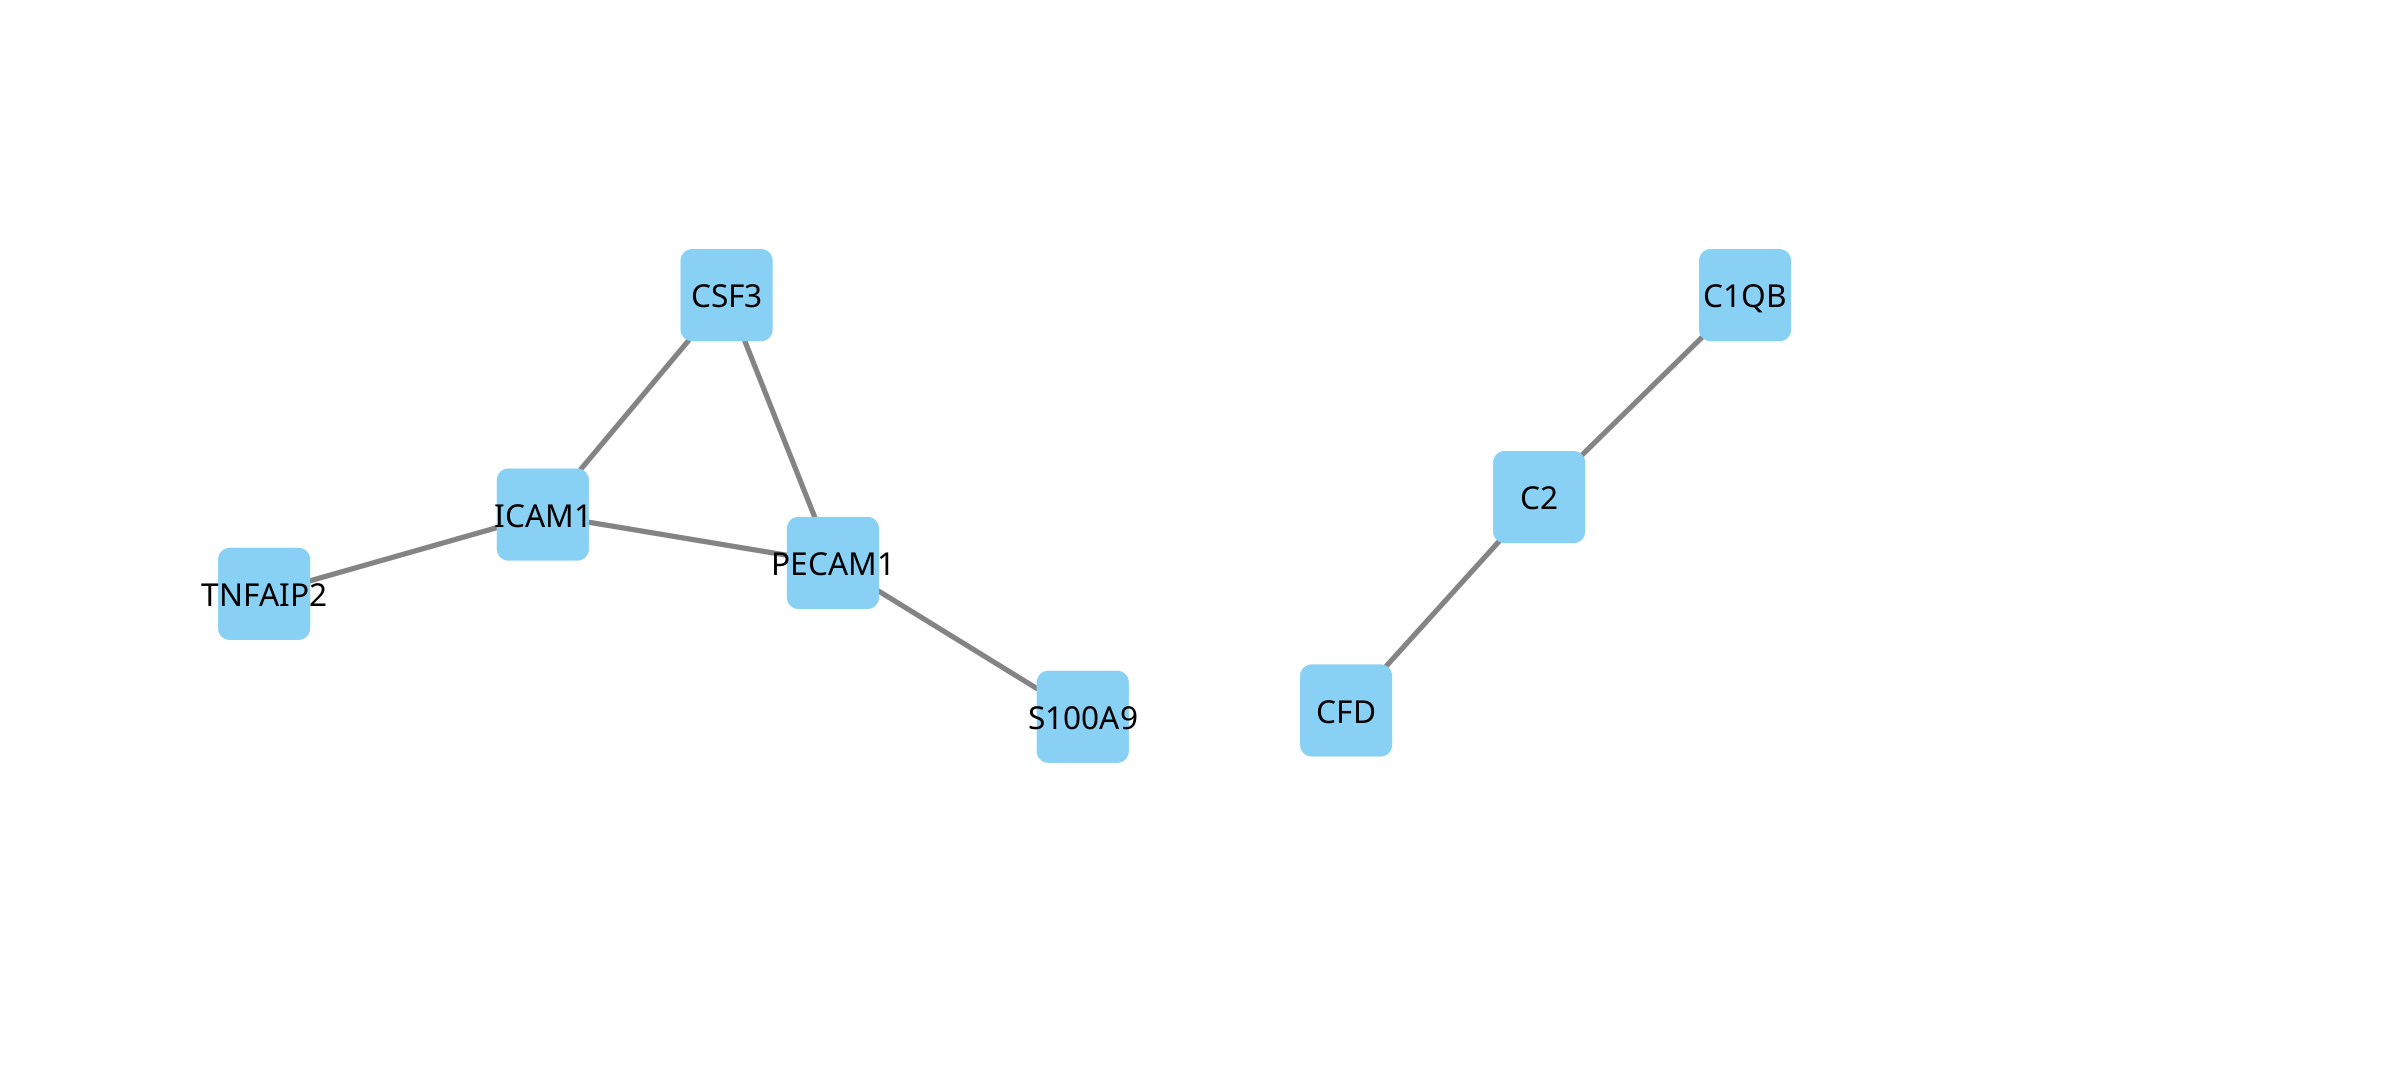

## Protein-Protein Interaction (PPI) Network Analysis
To understand the functional relationships between our top differentially expressed genes, we mapped their known interactions using STRING-DB and visualized the network in Cytoscape. As shown in the generated network, the mapped genes form two distinct, functionally related clusters:

* **Immune Signaling and Cell Adhesion:** The larger connected component links TNFAIP2, ICAM1, CSF3, PECAM1, and S100A9. The central positioning of nodes like ICAM1 and PECAM1 indicates a coordinated inflammatory and leukocyte adhesion response occurring within the PCOS cumulus cells.
* **Complement Cascade:** The second distinct component connects CFD, C2, and C1QB. These specific genes are core drivers of the complement system, reinforcing that localized immune dysregulation is a primary pathway distinguishing PCOS samples from controls.

10. Training the Machine Learning Classifier

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 3679  7563 10028] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [15945] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 4347  9218 15945] are constant.
  warnings.warn("Features %s are constant." % constant_features_

,Model,Accuracy (mean ± SD),ROC AUC (mean ± SD)
0,Baseline (always PCOS),0.57 ± 0.06,0.50 ± 0.00
1,Logistic Regression,0.57 ± 0.18,0.58 ± 0.23
2,Random Forest,0.56 ± 0.17,0.56 ± 0.23


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 3679  7563 10028] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [15945] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


              precision    recall  f1-score   support

     Control       0.44      0.47      0.46        17
        PCOS       0.59      0.57      0.58        23

    accuracy                           0.53        40
   macro avg       0.52      0.52      0.52        40
weighted avg       0.53      0.53      0.53        40



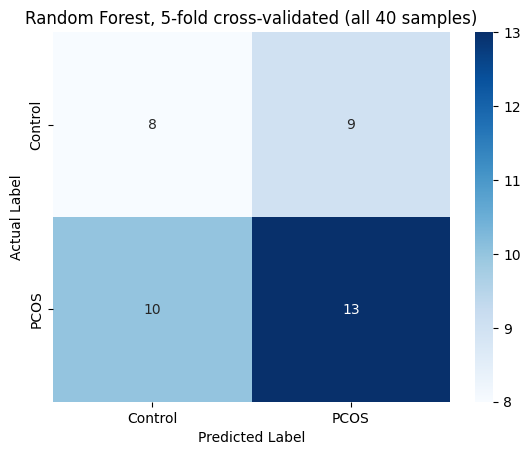

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 3679  7563 10028] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [15945] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


Genes selected in training folds (times out of 5):
id
RIOK1      4
MRPL46     4
GUCA1B     2
CEP57L1    2
DET1       2
          ..
CCL22      1
ARL3       1
FXYD6      1
GLE1       1
GNL3L      1
Length: 20, dtype: int64
Overlap with our 15 DESeq2 genes: []


In [34]:
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# All 19,216 filtered genes; gene selection now happens INSIDE each training fold (no leakage)
X = log_fpkm.T
y = metadata['condition'].map({'Control': 0, 'PCOS': 1}).values
K = 15  # same number of genes as our DESeq2 result

models = {
    'Baseline (always PCOS)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([('scale', StandardScaler()),
                                     ('select', SelectKBest(f_classif, k=K)),
                                     ('clf', LogisticRegression(max_iter=1000))]),
    'Random Forest': Pipeline([('select', SelectKBest(f_classif, k=K)),
                               ('clf', RandomForestClassifier(n_estimators=100, random_state=42))]),
}

# 5-fold cross-validation, repeated 10 times
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
summary = []
for name, model in models.items():
    acc = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    auc = cross_val_score(model, X, y, cv=cv, scoring='roc_auc')
    summary.append({'Model': name,
                    'Accuracy (mean ± SD)': f"{acc.mean():.2f} ± {acc.std():.2f}",
                    'ROC AUC (mean ± SD)': f"{auc.mean():.2f} ± {auc.std():.2f}"})
display(pd.DataFrame(summary))

# Confusion matrix: every woman predicted once, by a model that never saw her
rf = models['Random Forest']
y_pred = cross_val_predict(rf, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
print(classification_report(y, y_pred, target_names=['Control', 'PCOS']))

cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Control', 'PCOS'], yticklabels=['Control', 'PCOS'])
plt.title('Random Forest, 5-fold cross-validated (all 40 samples)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# Which genes get picked most often across folds, and do they match our DESeq2 genes?
counts = pd.Series(0, index=X.columns)
for train_idx, _ in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, y):
    sel = SelectKBest(f_classif, k=K).fit(X.iloc[train_idx], y[train_idx])
    counts[X.columns[sel.get_support()]] += 1
top = counts[counts > 0].sort_values(ascending=False)
print("Genes selected in training folds (times out of 5):")
print(top.head(20))
print("Overlap with our 15 DESeq2 genes:", sorted(set(top.index) & set(significant_genes)))

## Machine Learning Model Evaluation
We tested whether cumulus-cell gene expression can separate PCOS from control samples. To avoid data leakage, the 15 most different genes were chosen inside each training fold only, so test samples never influenced gene selection. We used 5-fold cross-validation repeated 10 times and compared the Random Forest with a baseline and a logistic regression model.

| Model | Accuracy (mean ± SD) | ROC AUC (mean ± SD) |
|---|---|---|
| Baseline (always predicts PCOS) | 0.57 ± 0.06 | 0.50 ± 0.00 |
| Logistic Regression | 0.57 ± 0.18 | 0.58 ± 0.23 |
| Random Forest | 0.56 ± 0.17 | 0.56 ± 0.23 |

**Confusion matrix (Random Forest, each of the 40 samples predicted once by a model that never saw it):**
* 13 of 23 PCOS samples and 8 of 17 controls were classified correctly (21 of 40, 53% accuracy).
* 10 PCOS samples were missed and 9 controls were wrongly labelled PCOS.
* PCOS: precision 0.59, recall 0.57. Control: precision 0.44, recall 0.47.

**Gene stability:** The genes chosen in each training fold changed from fold to fold. The most frequent (RIOK1, MRPL46) were picked in only 4 of 5 folds, and none overlapped with our 15 DESeq2 genes.

**Interpretation:** Once leakage was removed, the Random Forest performed at or below the 57.5% baseline of always predicting PCOS. Our earlier 75% came from a single 12-sample test set where the genes had been chosen using all 40 samples, so it was over-optimistic. With 40 samples, gene expression in cumulus cells does not reliably classify PCOS versus control. The 15 genes show a real group-level difference, but it is too small and variable to predict individual samples.

## Conclusions
Cumulus cells from women with PCOS showed a small but consistent expression difference compared with controls. We addressed our four objectives as follows:

1. **Data acquisition and QC:** We obtained and quality-checked 40 RNA-seq samples (23 PCOS, 17 control) from GEO (GSE277906). No missing, negative or duplicate values were found, and 19,216 genes passed filtering. PCA showed heavy overlap between groups, so there is no strong genome-wide separation.
2. **Differential expression:** PyDESeq2 identified 15 genes significant at padj < 0.05. All 15 were lower in PCOS, including S100A9, PECAM1, ICAM1, RUNX3, C1QB and CFD.
3. **Biological interpretation:** Enrichment analysis pointed to endothelial development, leukocyte adhesion, extracellular-matrix organisation and complement regulation. The STRING/Cytoscape network formed two clusters: immune signalling and adhesion (ICAM1, PECAM1, S100A9, CSF3, TNFAIP2) and the complement cascade (CFD, C2, C1QB). This suggests reduced immune and vascular activity in PCOS cumulus cells.
4. **Classification:** With leakage-free cross-validation, the Random Forest reached 53% accuracy, no better than the 57.5% baseline. The expression differences are real at group level but do not classify individual samples reliably.

## Limitations
A primary limitation of this study is the relatively small sample size used to train the machine learning model, which inherently increases the risk of overfitting the training data. Furthermore, our reliance on bulk RNA-sequencing means that the expression data is averaged across a large number of cells. Because of this averaging effect, we are currently unable to observe individual cellular differences or precisely measure the heterogeneity within the cumulus cell population itself.

Only 15 genes reached significance, so each enrichment term rests on two or three genes. Several significant genes are markers of immune and vascular cells, so lower levels in PCOS may partly reflect fewer of those cells in the samples rather than changes in cumulus cells themselves. All participants were undergoing IVF, and no clinical variables (age, BMI, insulin resistance) were available to adjust for. Finally, another analysis of this dataset (Sikiru et al., 2025) reported 3,245 differentially expressed genes, which shows how strongly results depend on the pipeline and thresholds used.

## Recommendations and Future Steps
To build upon these findings, we strongly recommend validating the expression levels of these specific 15 genes in a controlled wet-lab environment using RT-qPCR. Additionally, to confirm the diagnostic viability and real-world reliability of the classification model, future efforts must focus on training and evaluating the machine learning algorithms on a significantly larger, multi-hospital dataset.

## Recommendations
A much larger cohort, ideally several hundred samples, is needed before classification can be meaningfully tested.